Number of chunks: 333,763
Mean length: 2,231 characters
Median length: 1,829 characters
Minimum length: 14 characters
Maximum length: 4,999 characters
Percentiles:
  50th: 1,829 characters
  75th: 3,266 characters
  90th: 4,531 characters
  95th: 4,816 characters
  99th: 4,968 characters


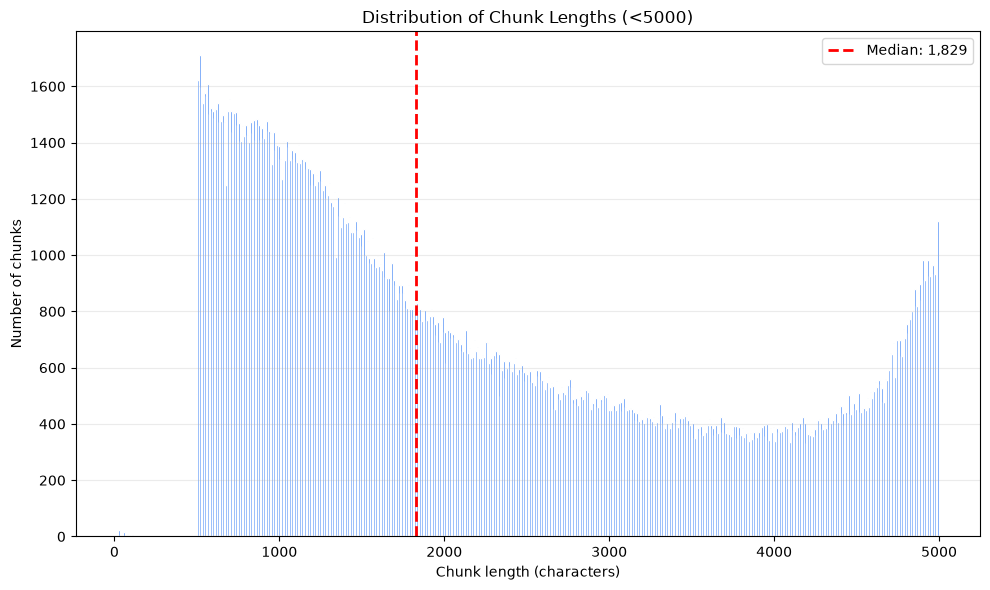

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

chunks_path = Path("../data/processed/chunks.jsonl")

chunk_lengths = []

with chunks_path.open("r", encoding="utf-8") as file:
    for line in file:
        chunk = json.loads(line)
        chunk_lengths.append(len(chunk["text"]))

lengths = np.asarray(chunk_lengths)
lengths = lengths[lengths < 5000]

print(f"Number of chunks: {len(lengths):,}")
print(f"Mean length: {lengths.mean():,.0f} characters")
print(f"Median length: {np.median(lengths):,.0f} characters")
print(f"Minimum length: {lengths.min():,} characters")
print(f"Maximum length: {lengths.max():,} characters")
print("Percentiles:")
for percentile in [50, 75, 90, 95, 99]:
    print(f"  {percentile}th: {np.percentile(lengths, percentile):,.0f} characters")

plt.figure(figsize=(10, 6))
plt.hist(lengths, bins=500, color="#3b82f6", edgecolor="white")

plt.axvline(
    np.median(lengths),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Median: {np.median(lengths):,.0f}",
)

plt.title("Distribution of Chunk Lengths (<5000)")
plt.xlabel("Chunk length (characters)")
plt.ylabel("Number of chunks")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.show()